# Stock Closing Price Prediction using Machine Learning Techniques
**Implementation of:** Vijh, Chandola, Tikkiwal & Kumar (2020), *Procedia Computer Science* 167, 599–606 (ICCIDS 2019).

**What the paper does**
- **Data:** 10 years of daily OHLCV from Yahoo Finance (5 Apr 2009 – 5 Apr 2019) for **Nike, Goldman Sachs, Johnson & Johnson, Pfizer, JP Morgan**.
- **Split:** train 06 Apr 2009 – 03 Apr 2017, test 04 Apr 2017 – 05 Apr 2019 (chronological, no shuffling).
- **Engineered inputs (Sec. 2.2/2.3):** `H-L`, `O-C`, `7-day MA`, `14-day MA`, `21-day MA`, `7-day STD`, `Volume`.
- **Target:** the **next day's closing price**.
- **Models:** an ANN (input → one hidden layer → 1 output neuron) and a Random Forest regressor.
- **Metrics:** RMSE, MAPE, MBE (Eqs. 1–3).

The paper does not give hyper-parameters (hidden units, epochs, number of trees), so reasonable defaults are used and stated below. A naive "tomorrow = today's close" baseline is added at the end as a sanity check; it is not in the paper.

In [1]:
# !pip install yfinance scikit-learn matplotlib seaborn pandas numpy   # uncomment if needed
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

from sklearn.neural_network import MLPRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.compose import TransformedTargetRegressor

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
SEED = 42
np.random.seed(SEED)

## 1. Configuration (same companies and dates as the paper)
Change `TICKERS`, `START`, `END`, `SPLIT_DATE` to run on any other stock(s).

In [2]:
TICKERS = {
    "NKE": "Nike",
    "GS":  "Goldman Sachs",
    "JPM": "JP Morgan Chase & Co.",
    "JNJ": "Johnson & Johnson",
    "PFE": "Pfizer Inc.",
}
START      = "2009-04-05"
END        = "2019-04-06"   # yfinance 'end' is exclusive -> includes 5 Apr 2019
SPLIT_DATE = "2017-04-04"   # first day of the test set (Table 1)

FEATURES = ["H-L", "O-C", "MA7", "MA14", "MA21", "STD7", "Volume"]
TARGET   = "Next_Close"

## 2. Download data from Yahoo Finance

In [3]:
import time
def download(ticker, retries=4):
    for k in range(retries):
        df = yf.download(ticker, start=START, end=END, auto_adjust=False, progress=False, multi_level_index=False)
        if len(df): return df[["Open", "High", "Low", "Close", "Volume"]].dropna()
        time.sleep(2 * (k + 1))          # Yahoo occasionally returns empty data; retry
    raise RuntimeError(f"No data for {ticker}")

data = {t: download(t) for t in TICKERS}
for t, df in data.items():
    print(f"{t:4s} {TICKERS[t]:24s} rows={len(df):5d}  {df.index.min().date()} -> {df.index.max().date()}")
data["NKE"].head()

NKE  Nike                     rows= 2518  2009-04-06 -> 2019-04-05
GS   Goldman Sachs            rows= 2518  2009-04-06 -> 2019-04-05
JPM  JP Morgan Chase & Co.    rows= 2518  2009-04-06 -> 2019-04-05
JNJ  Johnson & Johnson        rows= 2518  2009-04-06 -> 2019-04-05
PFE  Pfizer Inc.              rows= 2518  2009-04-06 -> 2019-04-05


,Open,High,Low,Close,Volume
Date,,,,,
2009-04-06,12.8200,12.8750,12.6150,12.8175,11080000
2009-04-07,12.5925,12.5950,12.3775,12.4650,11580000
2009-04-08,12.4900,12.6550,12.3625,12.5600,13103200
2009-04-09,12.8125,13.3750,12.6450,13.3175,18044400
2009-04-13,13.1825,13.3675,12.8975,13.2800,13202000


### 2.1 Exploratory plots: closing price and volume

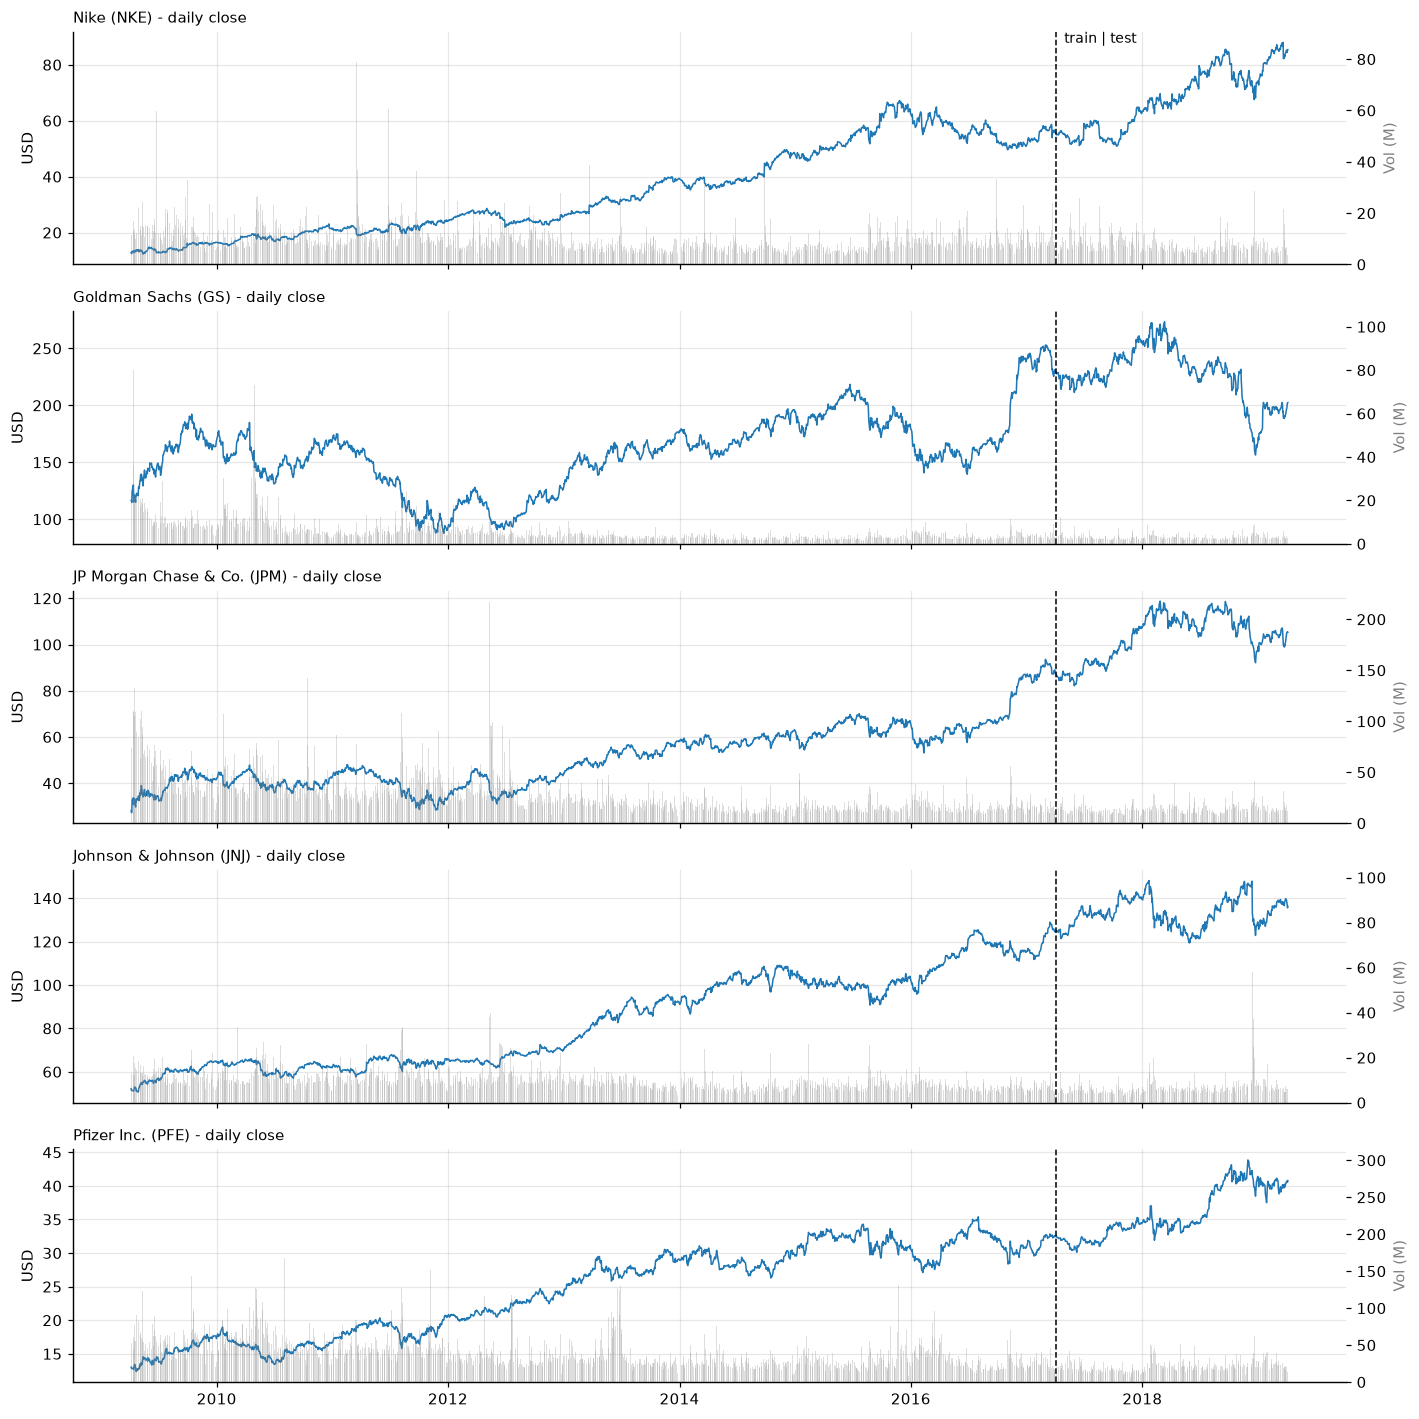

In [4]:
fig, axes = plt.subplots(len(TICKERS), 1, figsize=(13, 2.6 * len(TICKERS)), sharex=True)
for ax, (t, df) in zip(axes, data.items()):
    ax.plot(df.index, df["Close"], color="C0", lw=1)
    ax.axvline(pd.Timestamp(SPLIT_DATE), color="k", ls="--", lw=1)
    ax.set_title(f"{TICKERS[t]} ({t}) - daily close", loc="left", fontsize=10)
    ax.set_ylabel("USD")
    ax2 = ax.twinx()
    ax2.bar(df.index, df["Volume"] / 1e6, color="C7", alpha=0.25, width=1.5)
    ax2.set_ylabel("Vol (M)", color="C7"); ax2.grid(False)
axes[0].text(pd.Timestamp(SPLIT_DATE), axes[0].get_ylim()[1], "  train | test", va="top", fontsize=9)
plt.tight_layout(); plt.show()

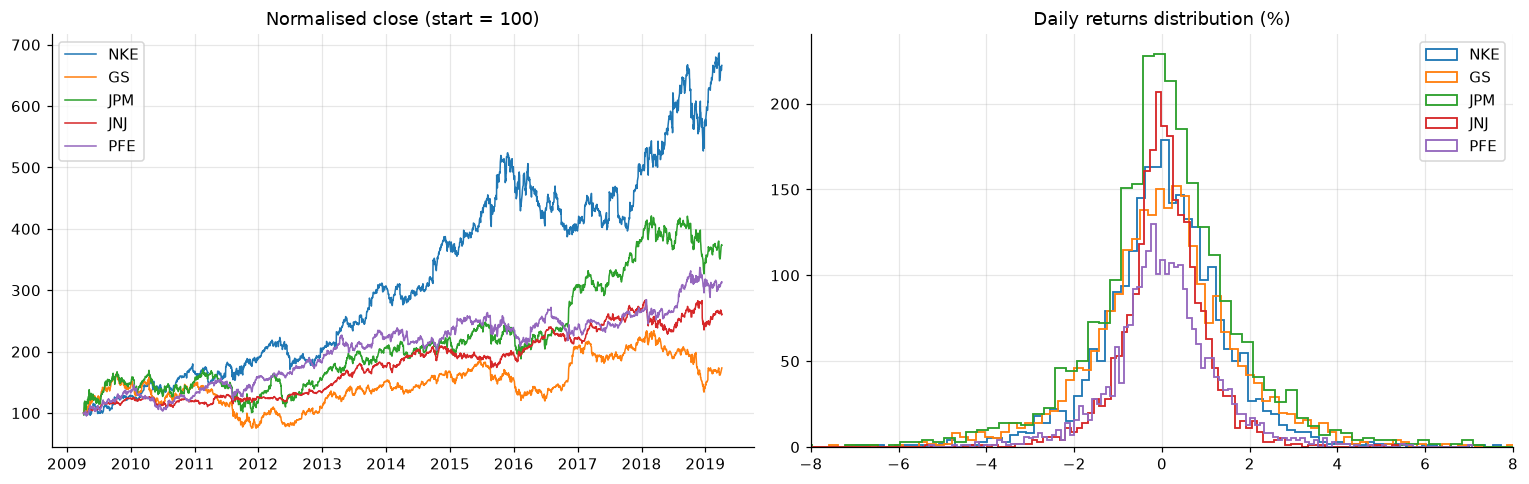

In [5]:
# Normalised performance (base = 100) and daily-return distribution
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for t, df in data.items():
    ax[0].plot(df.index, 100 * df["Close"] / df["Close"].iloc[0], lw=1, label=t)
    ax[1].hist(df["Close"].pct_change().dropna() * 100, bins=120, histtype="step", lw=1.2, label=t)
ax[0].set_title("Normalised close (start = 100)"); ax[0].legend()
ax[1].set_title("Daily returns distribution (%)"); ax[1].set_xlim(-8, 8); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. Feature engineering (Section 2.2)
| Variable | Definition |
|---|---|
| H-L | High − Low |
| O-C | Close − Open (the paper labels it O-C but describes it as "Close minus Open") |
| MA7 / MA14 / MA21 | 7/14/21-day moving average of Close |
| STD7 | 7-day rolling standard deviation of Close |
| Volume | traded volume |

Target: `Next_Close` = Close at *t+1*. Every feature uses information up to day *t* only, so nothing leaks from the future.

In [6]:
def make_features(df):
    d = df.copy()
    d["H-L"]  = d["High"] - d["Low"]
    d["O-C"]  = d["Close"] - d["Open"]
    d["MA7"]  = d["Close"].rolling(7).mean()
    d["MA14"] = d["Close"].rolling(14).mean()
    d["MA21"] = d["Close"].rolling(21).mean()
    d["STD7"] = d["Close"].rolling(7).std()
    d[TARGET] = d["Close"].shift(-1)
    d["Next_Date"] = pd.Series(d.index, index=d.index).shift(-1)   # date the target refers to
    return d.dropna()

feat = {t: make_features(df) for t, df in data.items()}
feat["NKE"][FEATURES + ["Close", TARGET]].tail()

,H-L,O-C,MA7,MA14,MA21,STD7,Volume,Close,Next_Close
Date,,,,,,,,,
2019-03-29,0.989998,-0.389999,83.892857,85.320001,85.415715,1.971588,6492000,84.209999,85.230003
2019-04-01,0.620003,0.190002,83.495714,85.305715,85.323810,1.084433,6737400,85.230003,84.370003
2019-04-02,1.099998,-0.629997,83.807143,85.194287,85.263334,0.951889,4433800,84.370003,84.470001
2019-04-03,0.739998,-0.430000,84.112857,85.022858,85.217144,0.711778,4080900,84.470001,85.279999
2019-04-04,1.019997,0.790001,84.384286,84.914286,85.224287,0.747126,3660700,85.279999,85.400002


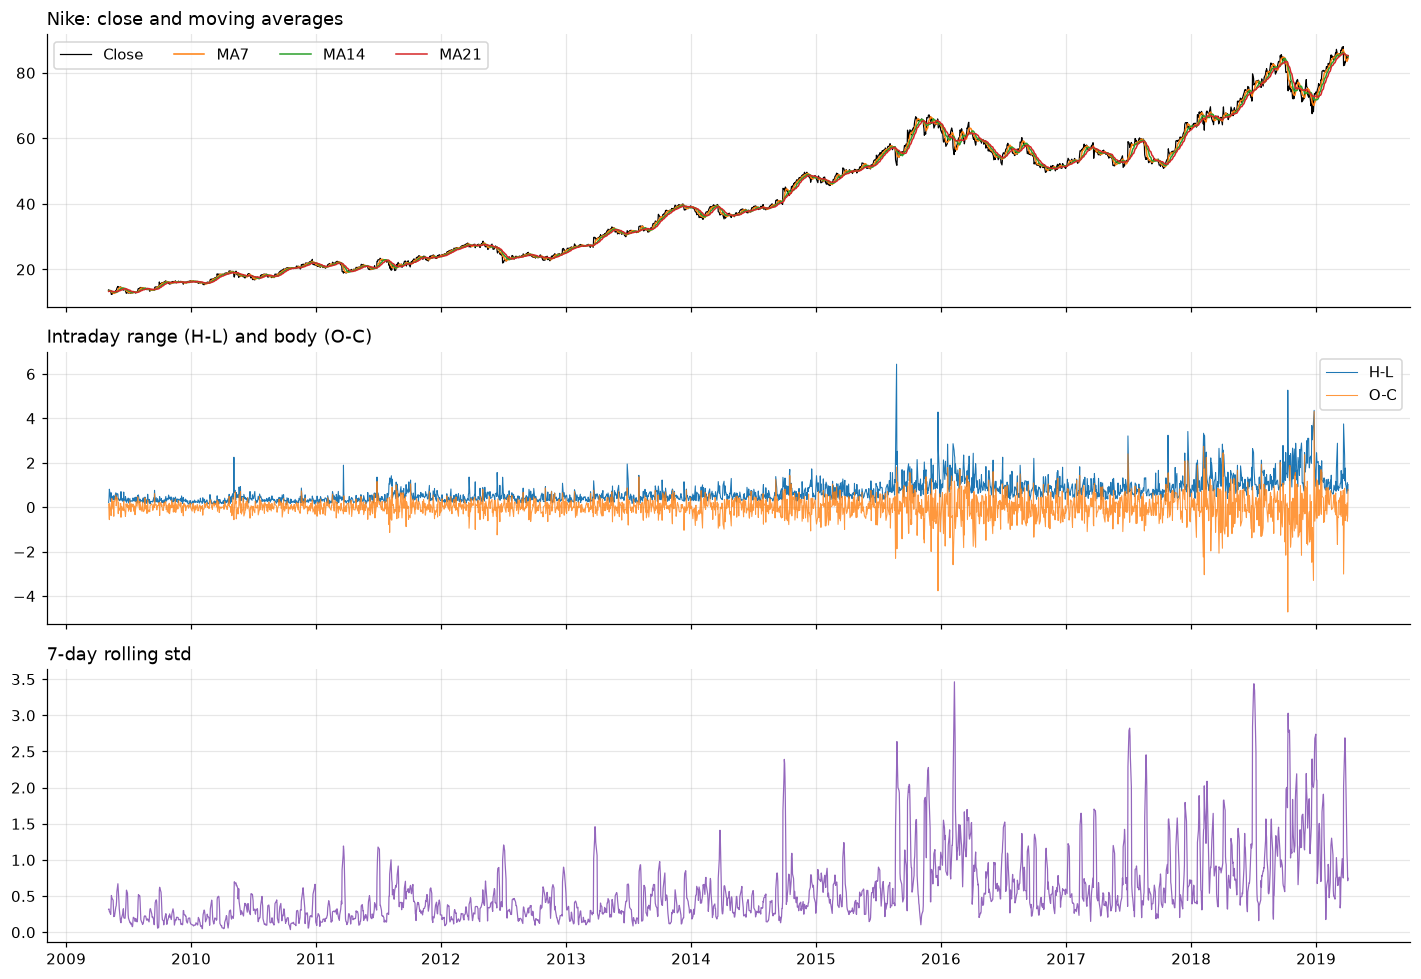

In [7]:
# Engineered features for one stock (Nike)
t = "NKE"; d = feat[t]
fig, ax = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
ax[0].plot(d.index, d["Close"], lw=0.8, color="k", label="Close")
for c, col in zip(["MA7", "MA14", "MA21"], ["C1", "C2", "C3"]):
    ax[0].plot(d.index, d[c], lw=1, color=col, label=c)
ax[0].legend(ncol=4); ax[0].set_title(f"{TICKERS[t]}: close and moving averages", loc="left")
ax[1].plot(d.index, d["H-L"], lw=0.7, label="H-L"); ax[1].plot(d.index, d["O-C"], lw=0.7, label="O-C", alpha=0.8)
ax[1].legend(); ax[1].set_title("Intraday range (H-L) and body (O-C)", loc="left")
ax[2].plot(d.index, d["STD7"], lw=0.8, color="C4"); ax[2].set_title("7-day rolling std", loc="left")
plt.tight_layout(); plt.show()

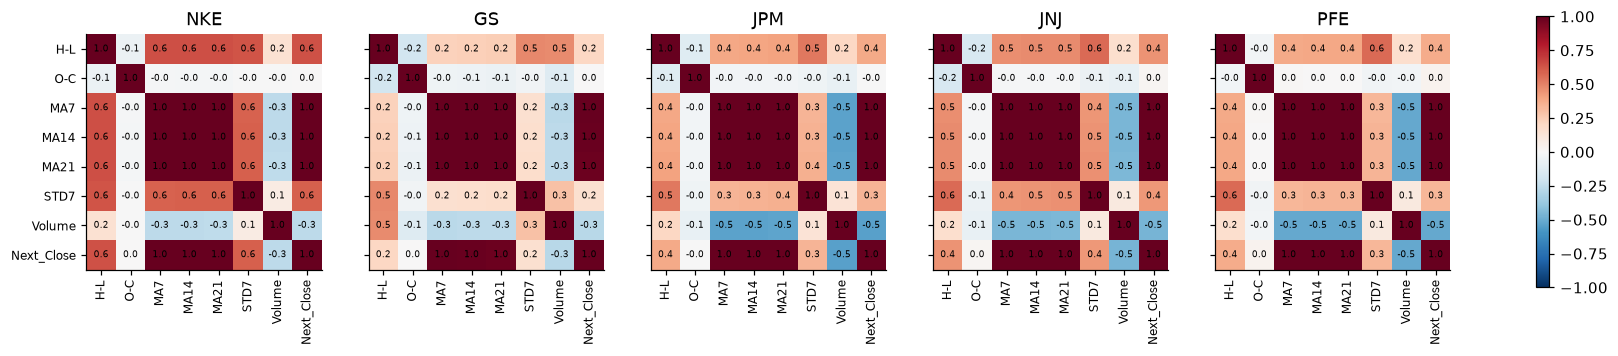

In [8]:
# Correlation of inputs with the target
fig, axes = plt.subplots(1, len(TICKERS), figsize=(4 * len(TICKERS), 4))
for ax, t in zip(axes, TICKERS):
    c = feat[t][FEATURES + [TARGET]].corr()
    im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(c))); ax.set_xticklabels(c.columns, rotation=90, fontsize=8)
    ax.set_yticks(range(len(c))); ax.set_yticklabels(c.columns if ax is axes[0] else [], fontsize=8)
    ax.set_title(t); ax.grid(False)
    for i in range(len(c)):
        for j in range(len(c)):
            ax.text(j, i, f"{c.iloc[i, j]:.1f}", ha="center", va="center", fontsize=6)
fig.colorbar(im, ax=axes, shrink=0.8); plt.show()

## 4. Train / test split (Table 1)

In [9]:
def split(d):
    tr, te = d[d.index < SPLIT_DATE], d[d.index >= SPLIT_DATE]
    return tr[FEATURES], tr[TARGET], te[FEATURES], te[TARGET], te

splits = {t: split(feat[t]) for t in TICKERS}
pd.DataFrame({t: {"train_start": s[0].index.min().date(), "train_end": s[0].index.max().date(), "n_train": len(s[0]),
                  "test_start": s[2].index.min().date(), "test_end": s[2].index.max().date(), "n_test": len(s[2])}
              for t, s in splits.items()}).T

,train_start,train_end,n_train,test_start,test_end,n_test
NKE,2009-05-05,2017-04-03,1993,2017-04-04,2019-04-04,504
GS,2009-05-05,2017-04-03,1993,2017-04-04,2019-04-04,504
JPM,2009-05-05,2017-04-03,1993,2017-04-04,2019-04-04,504
JNJ,2009-05-05,2017-04-03,1993,2017-04-04,2019-04-04,504
PFE,2009-05-05,2017-04-03,1993,2017-04-04,2019-04-04,504


## 5. Models
**ANN (Sec. 2.3, Fig. 1):** 7 inputs → 1 hidden layer → 1 output neuron. Inputs and target are standardised (fit on train only). Settings: 64 ReLU hidden units, Adam, early stopping on a 10% validation slice.

**Random Forest (Sec. 2.4):** `RandomForestRegressor` with 500 trees on the same 7 inputs. Trees are scale-invariant, so no scaling is applied.

In [10]:
def build_ann():
    mlp = MLPRegressor(hidden_layer_sizes=(64,), activation="relu", solver="adam",
                       learning_rate_init=1e-3, alpha=1e-4, max_iter=2000,
                       early_stopping=True, validation_fraction=0.1, n_iter_no_change=50,
                       random_state=SEED)
    return TransformedTargetRegressor(regressor=make_pipeline(StandardScaler(), mlp),
                                      transformer=StandardScaler())

def build_rf():
    return RandomForestRegressor(n_estimators=500, min_samples_leaf=1, max_features=1.0,
                                 n_jobs=-1, random_state=SEED)

# Evaluation metrics, Eqs. (1)-(3). MAPE uses absolute errors, as is standard.
def rmse(o, f): return float(np.sqrt(np.mean((o - f) ** 2)))
def mape(o, f): return float(np.mean(np.abs((o - f) / o)) * 100)
def mbe(o, f):  return float(np.mean(o - f))

In [11]:
models, preds, rows = {}, {}, []
for t, (Xtr, ytr, Xte, yte, te) in splits.items():
    ann = build_ann().fit(Xtr, ytr)
    rf  = build_rf().fit(Xtr, ytr)
    p = pd.DataFrame({"Actual": yte.values,
                      "ANN": ann.predict(Xte),
                      "RF":  rf.predict(Xte),
                      "Naive": te["Close"].values},   # baseline: tomorrow = today
                     index=pd.DatetimeIndex(te["Next_Date"], name="Date"))
    models[t], preds[t] = {"ANN": ann, "RF": rf}, p
    for m in ["ANN", "RF", "Naive"]:
        rows.append({"Ticker": t, "Company": TICKERS[t], "Model": m,
                     "RMSE": rmse(p.Actual, p[m]), "MAPE (%)": mape(p.Actual, p[m]), "MBE": mbe(p.Actual, p[m])})
    print(f"{t}: done")
results = pd.DataFrame(rows)

NKE: done


GS: done


JPM: done


JNJ: done


PFE: done


## 6. Results: Table 2 replication

In [12]:
tbl = results[results.Model != "Naive"].pivot(index="Company", columns="Model", values=["RMSE", "MAPE (%)", "MBE"])
tbl = tbl.swaplevel(axis=1).sort_index(axis=1, level=0)[["ANN", "RF"]]
tbl = tbl.reindex(columns=["RMSE", "MAPE (%)", "MBE"], level=1).reindex([TICKERS[t] for t in TICKERS])
tbl.round(4)

Model                     ANN                        RF                  
                         RMSE MAPE (%)     MBE     RMSE MAPE (%)      MBE
Company                                                                  
Nike                   2.0512   2.2250  0.5063  10.0342   9.0979   6.6764
Goldman Sachs          5.3968   1.7917  0.5103  10.5842   3.7381  -3.1078
JP Morgan Chase & Co.  2.2333   1.5532  0.2192  16.2254  12.6979  13.4564
Johnson & Johnson      3.5362   1.6142 -0.0842   9.7944   5.7440   7.6294
Pfizer Inc.            0.6235   1.2278  0.1081   3.8507   6.2312   2.3015

In [13]:
# Values reported in the paper's Table 2, for side-by-side comparison
paper = pd.DataFrame({
    "Company": ["Nike", "Goldman Sachs", "JP Morgan Chase & Co.", "Johnson & Johnson", "Pfizer Inc."],
    "ANN RMSE": [1.10, 3.30, 1.28, 1.54, 0.42], "ANN MAPE (%)": [1.07, 1.09, 0.89, 0.70, 0.77],
    "RF RMSE":  [1.29, 3.40, 1.41, 1.53, 0.43], "RF MAPE (%)":  [1.14, 1.01, 0.93, 0.75, 0.80],
}).set_index("Company")
ours = pd.DataFrame({
    "ANN RMSE": tbl[("ANN", "RMSE")], "ANN MAPE (%)": tbl[("ANN", "MAPE (%)")],
    "RF RMSE":  tbl[("RF", "RMSE")],  "RF MAPE (%)":  tbl[("RF", "MAPE (%)")],
})
pd.concat({"Paper": paper, "This notebook": ours}, axis=1).round(2)

Paper                                  This notebook  \
                      ANN RMSE ANN MAPE (%) RF RMSE RF MAPE (%)      ANN RMSE   
Company                                                                         
Nike                      1.10         1.07    1.29        1.14          2.05   
Goldman Sachs             3.30         1.09    3.40        1.01          5.40   
JP Morgan Chase & Co.     1.28         0.89    1.41        0.93          2.23   
Johnson & Johnson         1.54         0.70    1.53        0.75          3.54   
Pfizer Inc.               0.42         0.77    0.43        0.80          0.62   

                                                        
                      ANN MAPE (%) RF RMSE RF MAPE (%)  
Company                                                 
Nike                          2.22   10.03        9.10  
Goldman Sachs                 1.79   10.58        3.74  
JP Morgan Chase & Co.         1.55   16.23       12.70  
Johnson & Johnson             1.61    9.79        5.74  
Pfizer Inc.                   1.23    3.85        6.23

### 6.1 Predicted vs original closing price: ANN (Fig. 2)

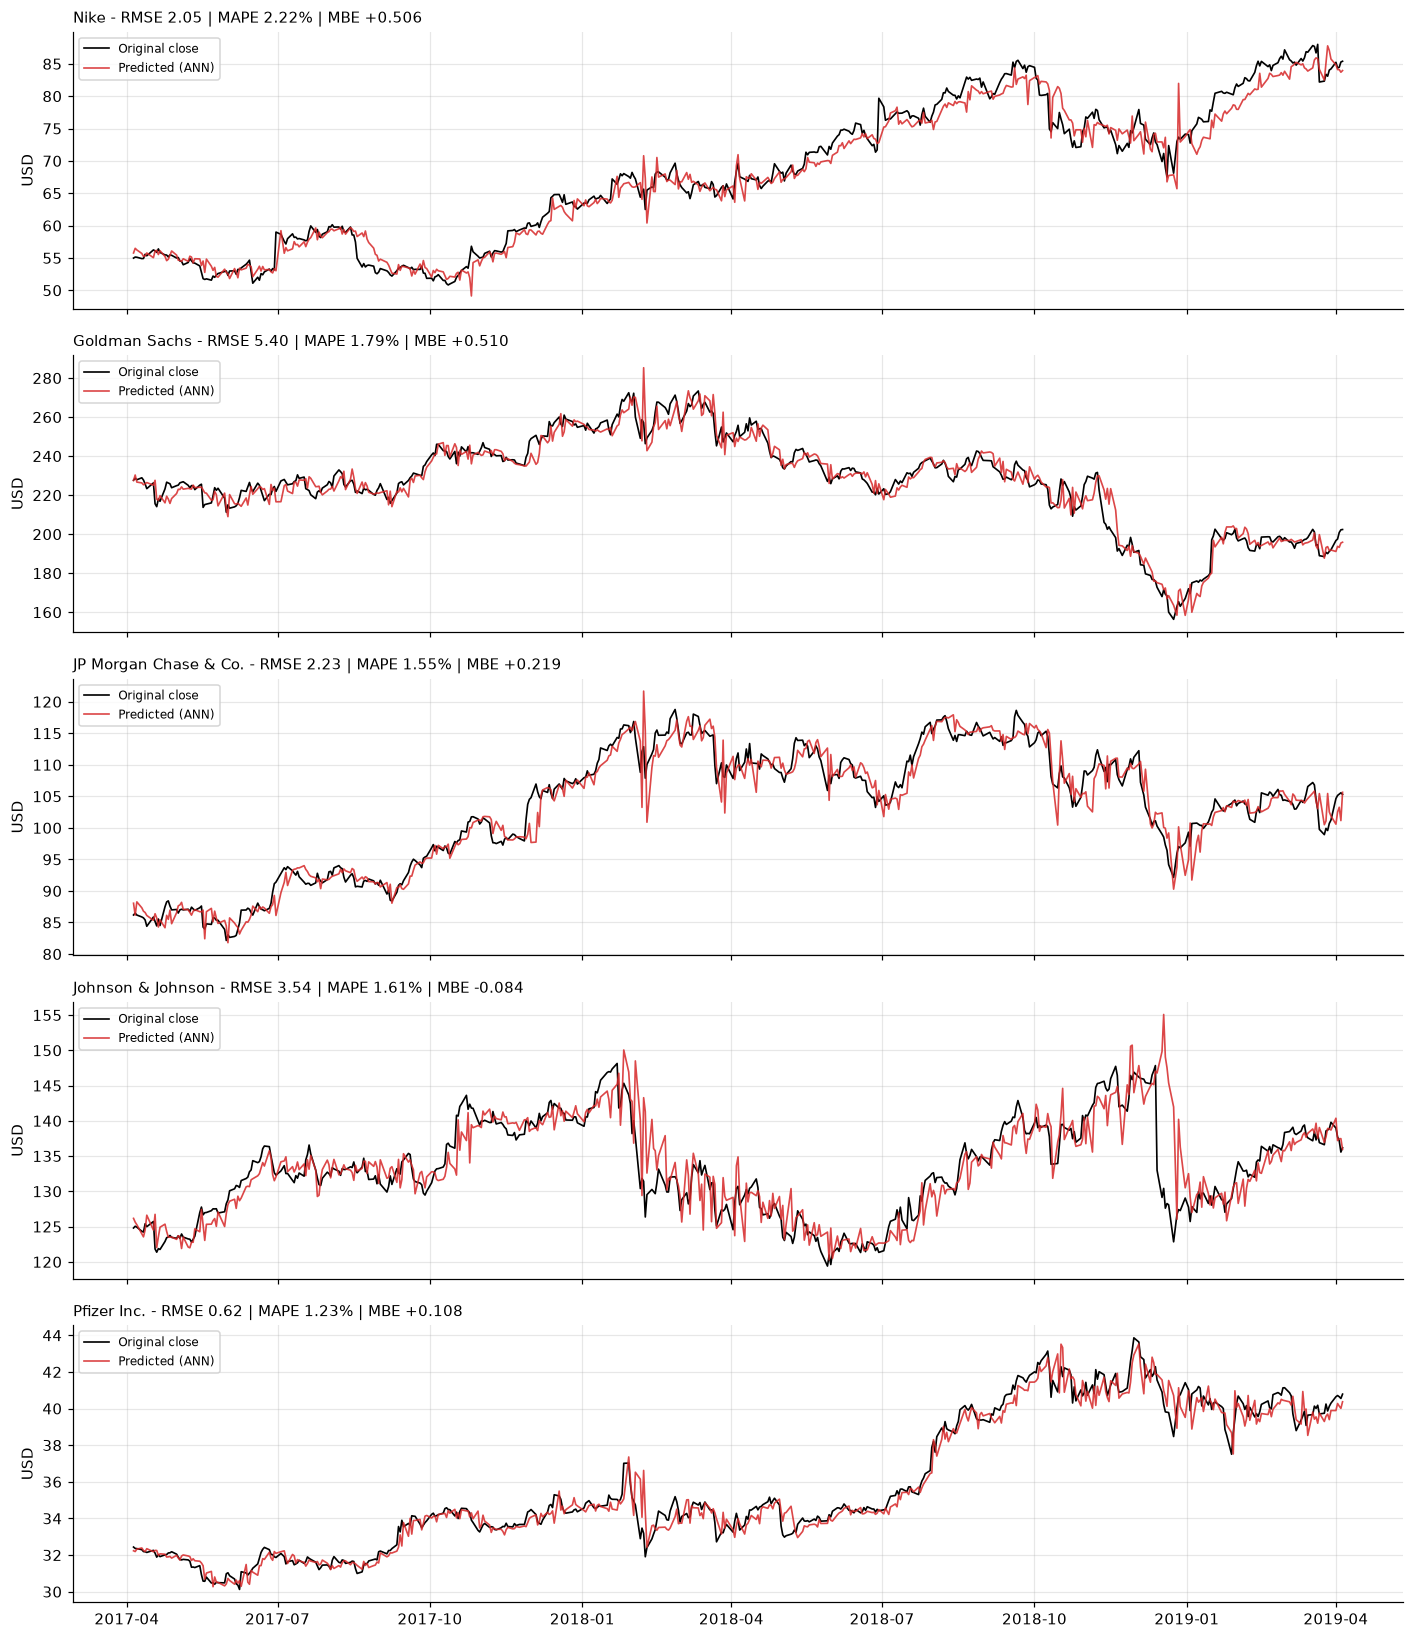

In [14]:
def plot_pred(model, color):
    fig, axes = plt.subplots(len(TICKERS), 1, figsize=(13, 3 * len(TICKERS)), sharex=True)
    for ax, t in zip(axes, TICKERS):
        p = preds[t]
        ax.plot(p.index, p.Actual, color="k", lw=1.1, label="Original close")
        ax.plot(p.index, p[model], color=color, lw=1.1, alpha=0.85, label=f"Predicted ({model})")
        r = results[(results.Ticker == t) & (results.Model == model)].iloc[0]
        ax.set_title(f"{TICKERS[t]} - RMSE {r.RMSE:.2f} | MAPE {r['MAPE (%)']:.2f}% | MBE {r.MBE:+.3f}",
                     loc="left", fontsize=10)
        ax.set_ylabel("USD"); ax.legend(loc="upper left", fontsize=8)
    plt.tight_layout(); plt.show()

plot_pred("ANN", "C3")

### 6.2 Predicted vs original closing price: Random Forest (Fig. 3)

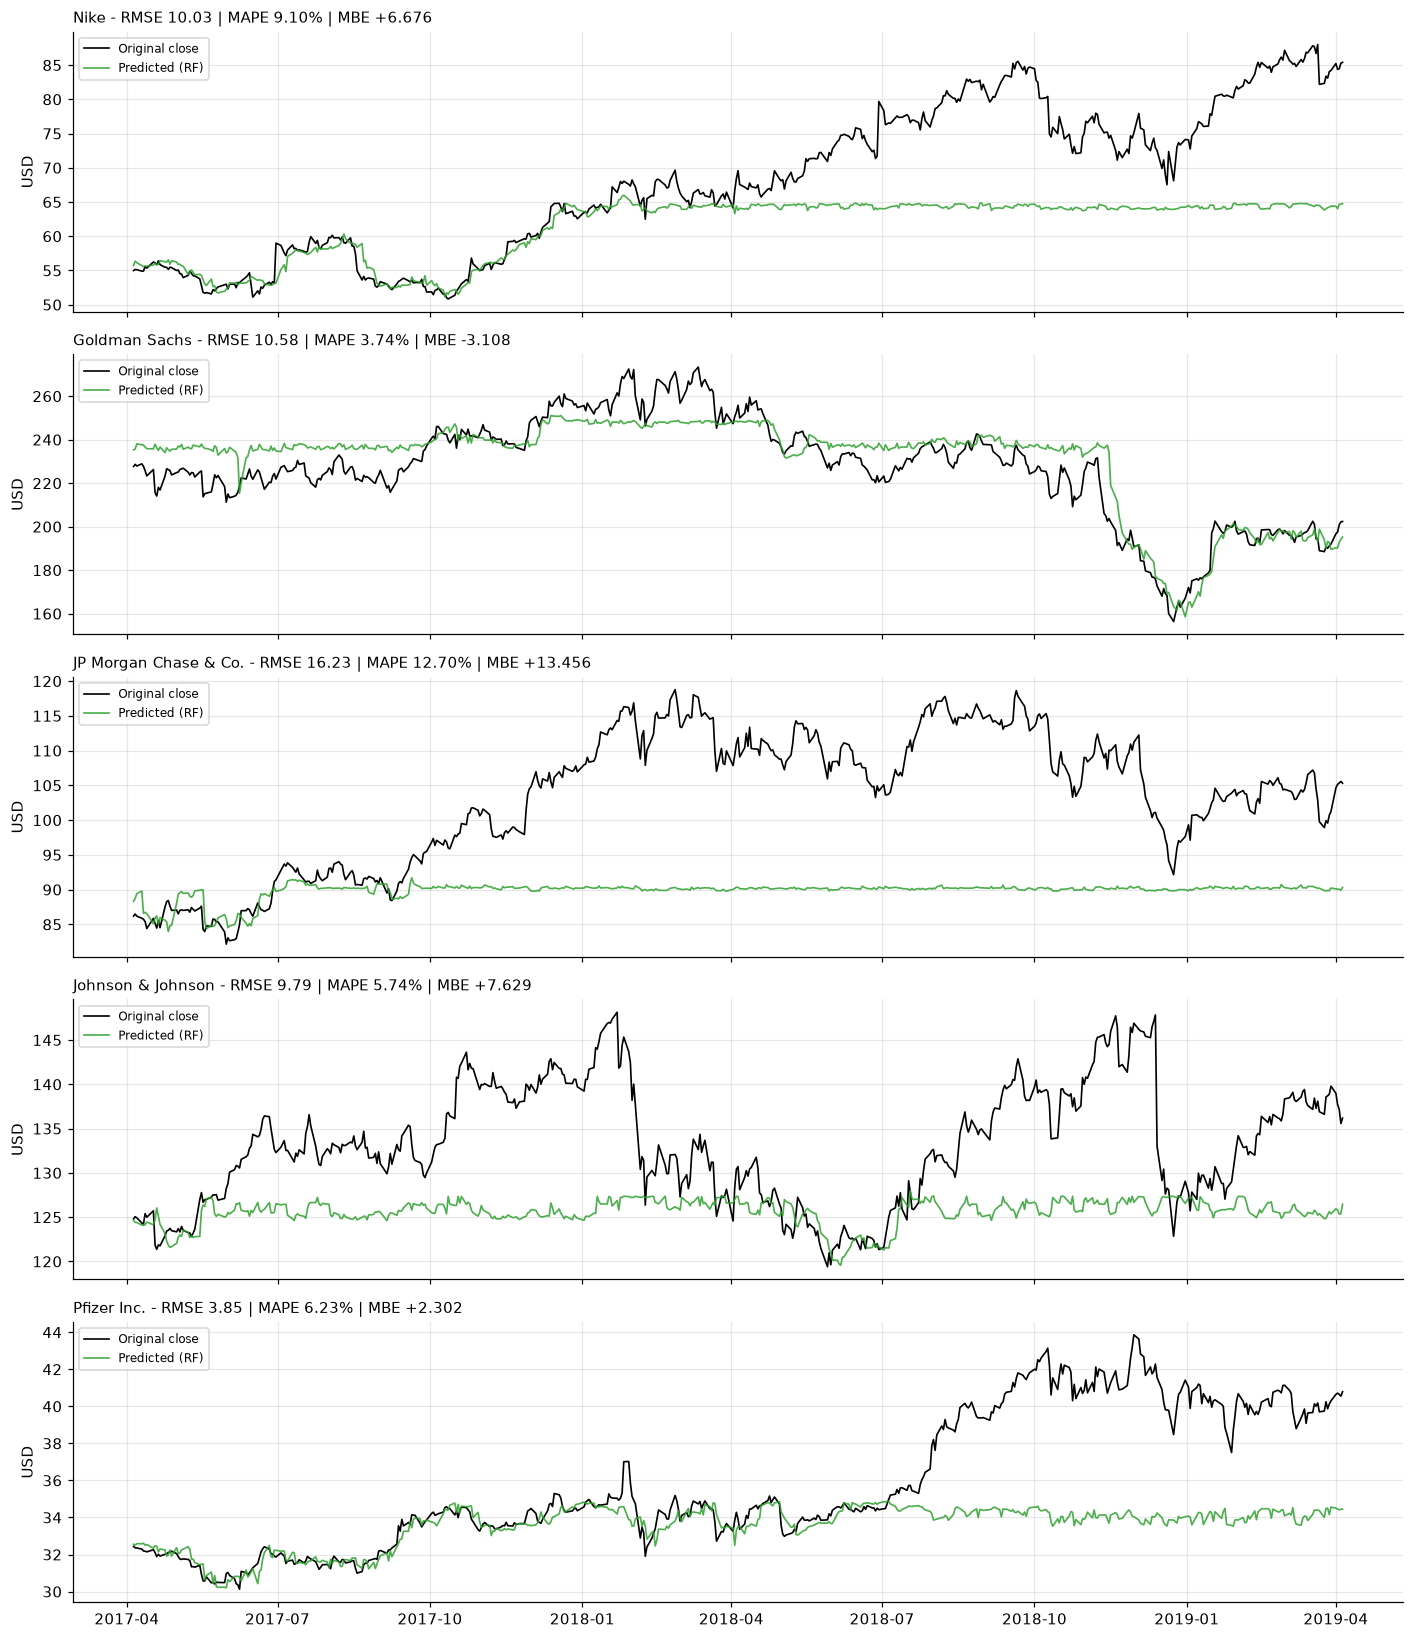

In [15]:
plot_pred("RF", "C2")

### 6.3 Zoom: last 90 test days

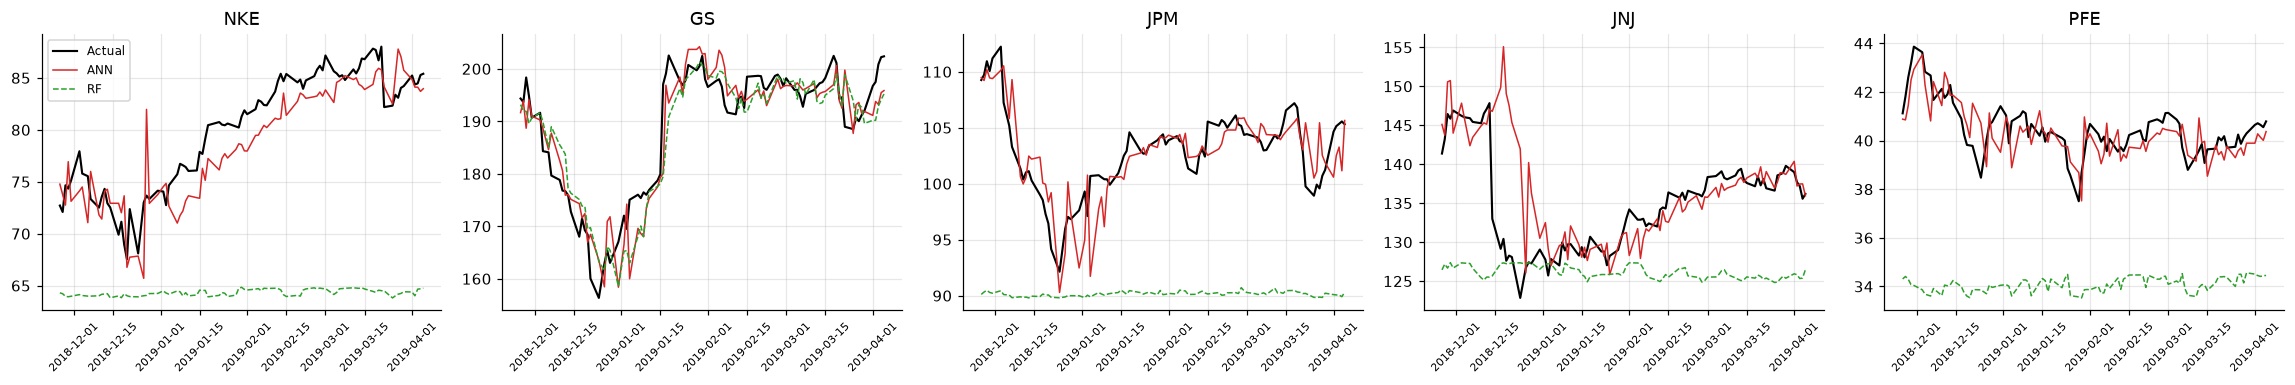

In [16]:
fig, axes = plt.subplots(1, len(TICKERS), figsize=(4.2 * len(TICKERS), 3.6))
for ax, t in zip(axes, TICKERS):
    p = preds[t].iloc[-90:]
    ax.plot(p.index, p.Actual, "k-", lw=1.4, label="Actual")
    ax.plot(p.index, p.ANN, "C3-", lw=1, label="ANN")
    ax.plot(p.index, p.RF, "C2--", lw=1, label="RF")
    ax.set_title(t); ax.tick_params(axis="x", rotation=45, labelsize=7)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

### 6.4 Scatter: predicted vs actual

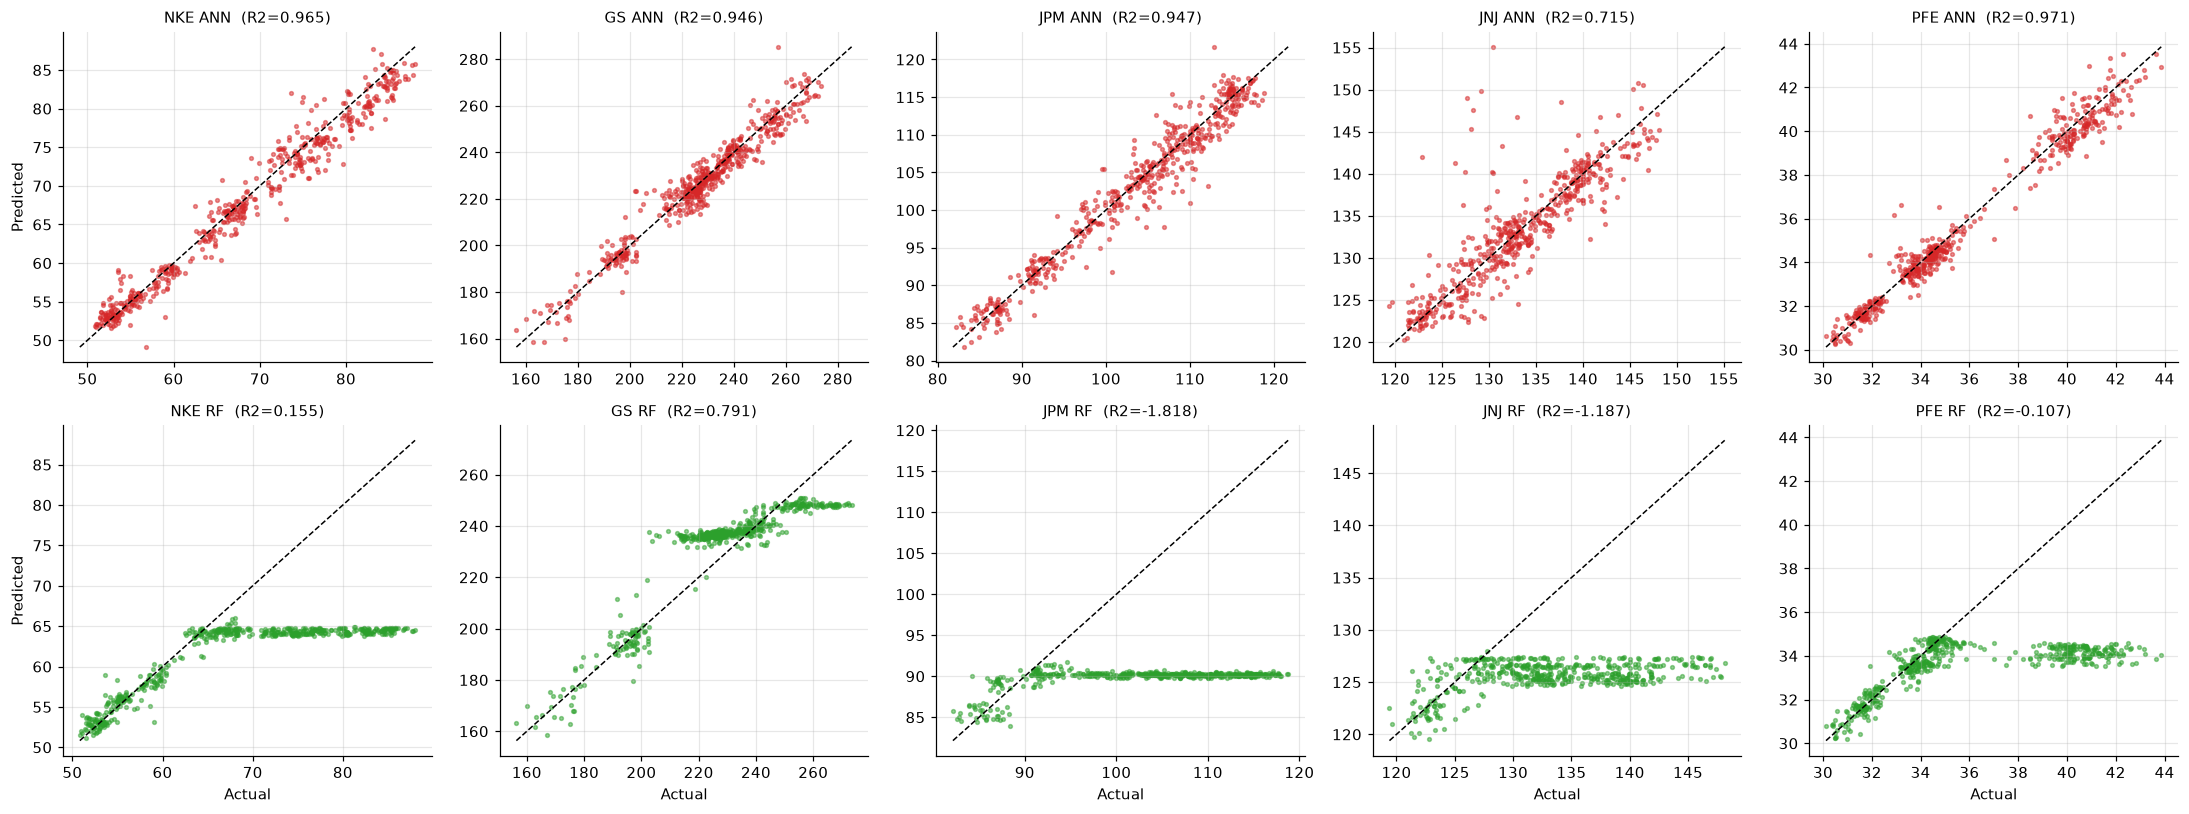

In [17]:
fig, axes = plt.subplots(2, len(TICKERS), figsize=(4 * len(TICKERS), 7.5))
for j, t in enumerate(TICKERS):
    p = preds[t]
    for i, (m, c) in enumerate([("ANN", "C3"), ("RF", "C2")]):
        ax = axes[i, j]
        ax.scatter(p.Actual, p[m], s=6, alpha=0.5, color=c)
        lo, hi = p[["Actual", m]].min().min(), p[["Actual", m]].max().max()
        ax.plot([lo, hi], [lo, hi], "k--", lw=1)
        r2 = 1 - ((p.Actual - p[m]) ** 2).sum() / ((p.Actual - p.Actual.mean()) ** 2).sum()
        ax.set_title(f"{t} {m}  (R2={r2:.3f})", fontsize=10)
        if j == 0: ax.set_ylabel("Predicted")
        if i == 1: ax.set_xlabel("Actual")
plt.tight_layout(); plt.show()

### 6.5 Residual analysis

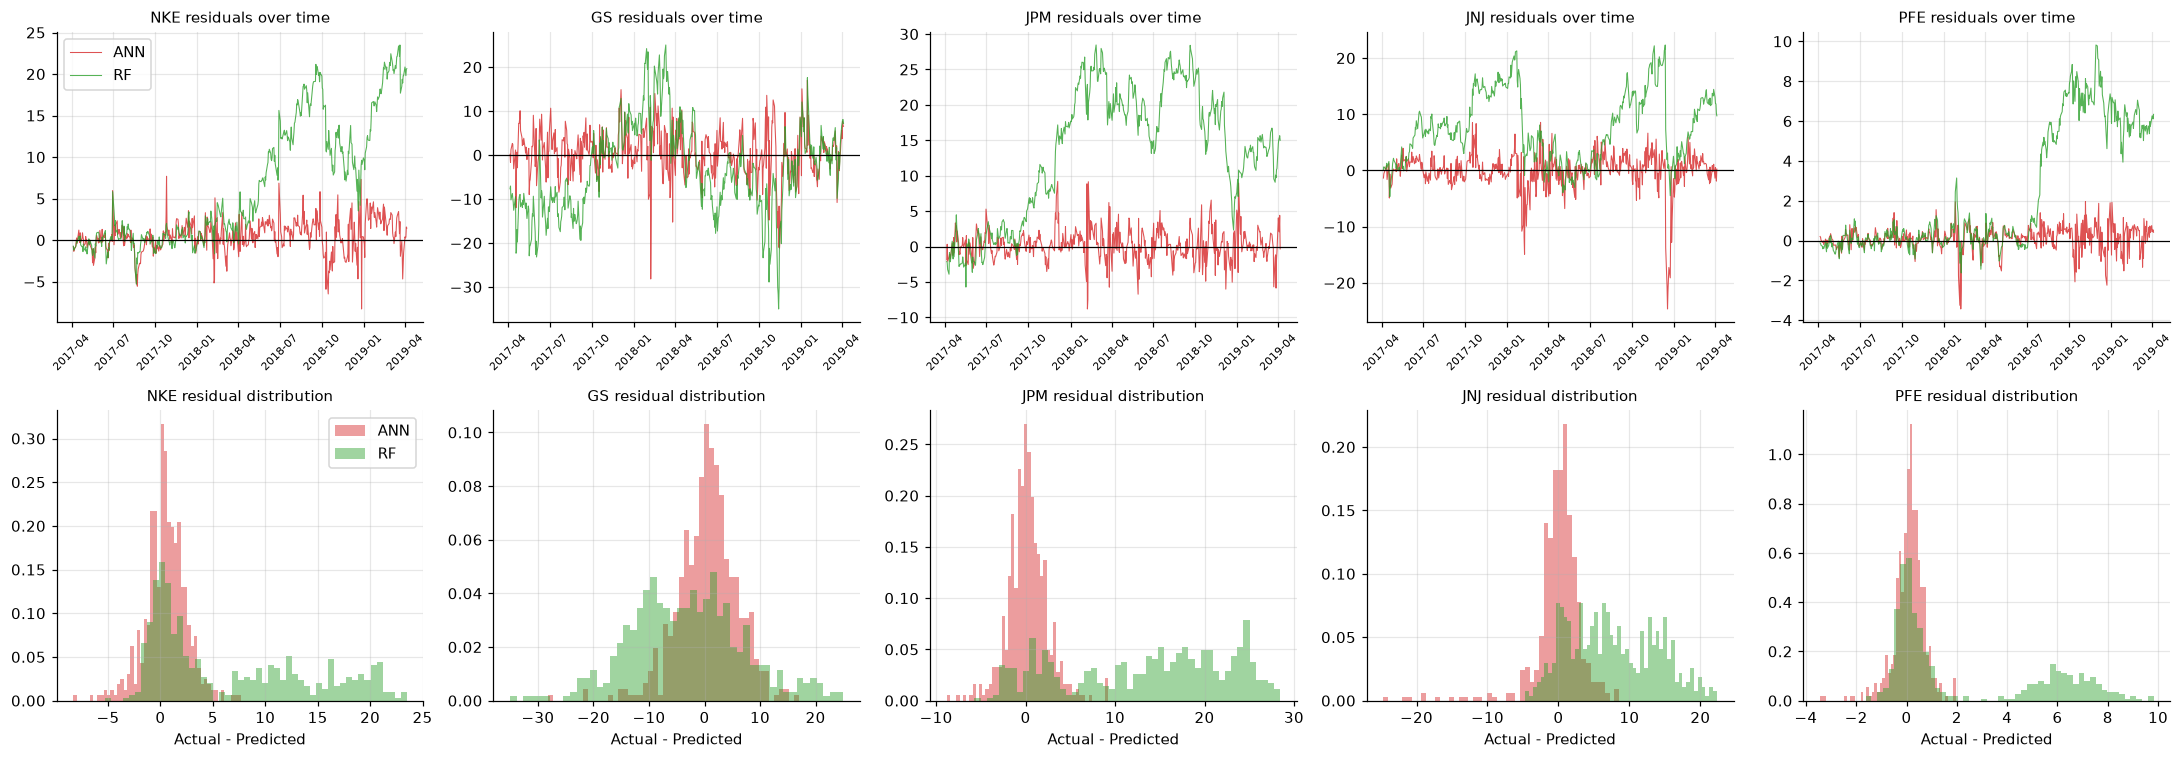

In [18]:
fig, axes = plt.subplots(2, len(TICKERS), figsize=(4 * len(TICKERS), 7))
for j, t in enumerate(TICKERS):
    p = preds[t]
    for m, c in [("ANN", "C3"), ("RF", "C2")]:
        e = p.Actual - p[m]
        axes[0, j].plot(p.index, e, color=c, lw=0.7, alpha=0.8, label=m)
        axes[1, j].hist(e, bins=50, color=c, alpha=0.45, label=m, density=True)
    axes[0, j].axhline(0, color="k", lw=0.8); axes[0, j].set_title(f"{t} residuals over time", fontsize=10)
    axes[0, j].tick_params(axis="x", rotation=45, labelsize=7)
    axes[1, j].set_title(f"{t} residual distribution", fontsize=10); axes[1, j].set_xlabel("Actual - Predicted")
axes[0, 0].legend(); axes[1, 0].legend(); plt.tight_layout(); plt.show()

### 6.6 Metric comparison: ANN vs RF

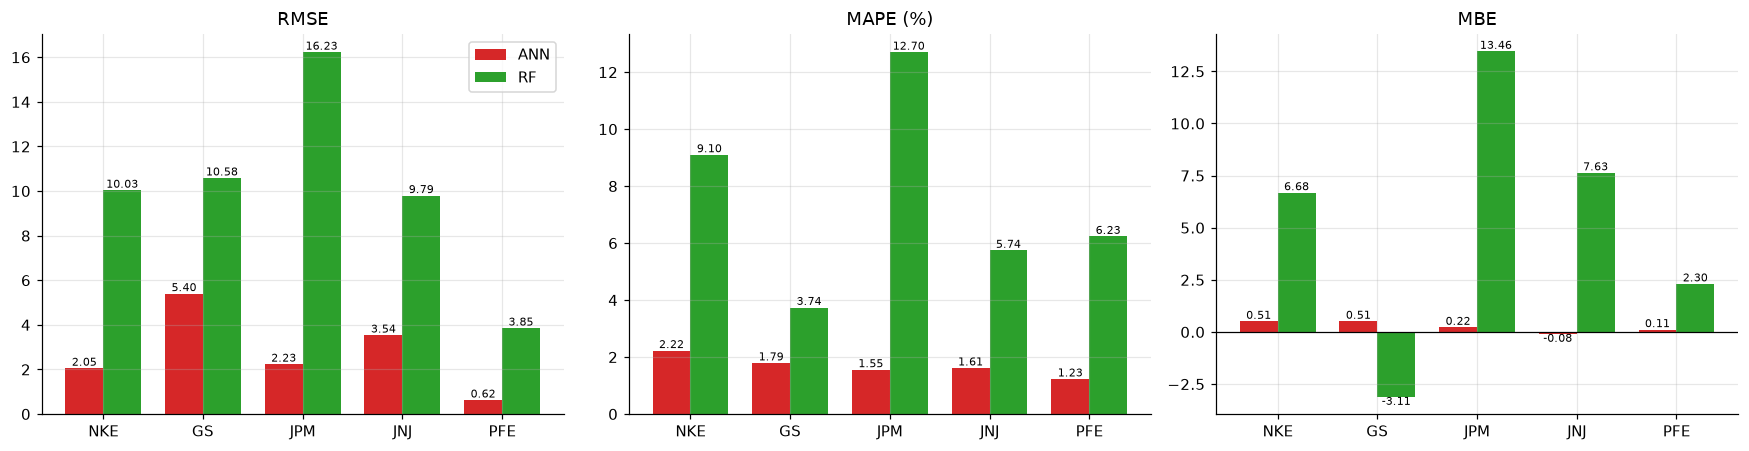

In [19]:
r = results[results.Model != "Naive"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
x = np.arange(len(TICKERS)); w = 0.38
for ax, metric in zip(axes, ["RMSE", "MAPE (%)", "MBE"]):
    for k, (m, c) in enumerate([("ANN", "C3"), ("RF", "C2")]):
        v = r[r.Model == m].set_index("Ticker").loc[list(TICKERS), metric]
        b = ax.bar(x + (k - 0.5) * w, v, w, color=c, label=m)
        ax.bar_label(b, fmt="%.2f", fontsize=7)
    ax.set_xticks(x); ax.set_xticklabels(list(TICKERS)); ax.set_title(metric)
    if metric == "MBE": ax.axhline(0, color="k", lw=0.8)
axes[0].legend(); plt.tight_layout(); plt.show()

### 6.7 ANN training curve and RF feature importance

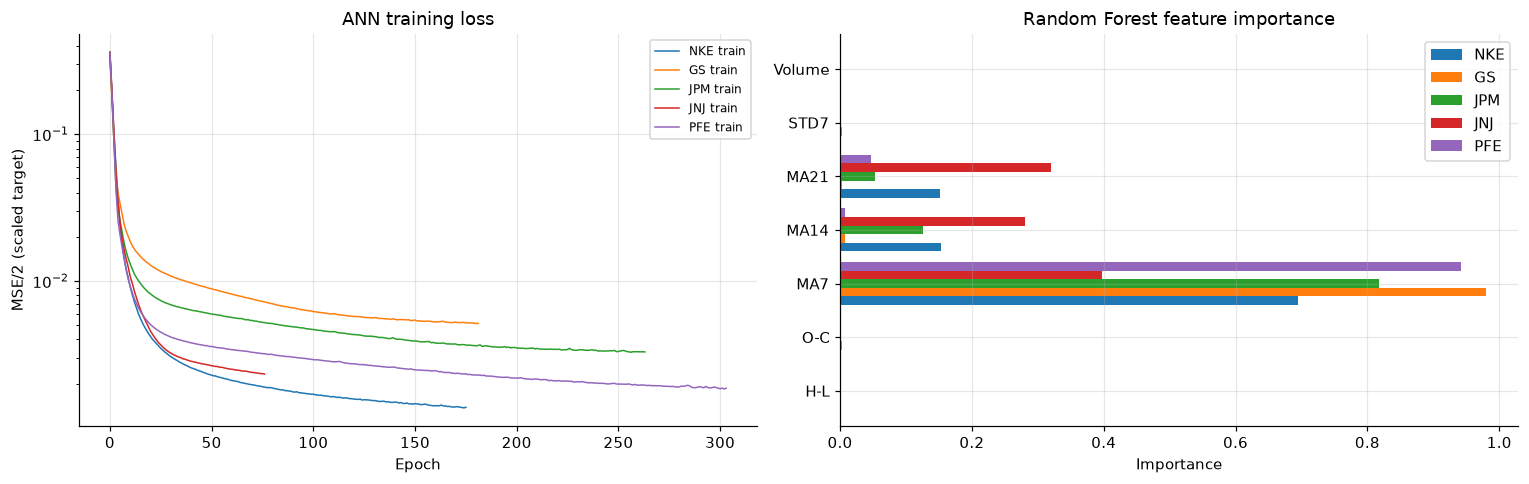

,NKE,GS,JPM,JNJ,PFE
H-L,0.000,0.002,0.001,0.000,0.000
O-C,0.000,0.004,0.001,0.001,0.001
MA7,0.694,0.979,0.817,0.398,0.942
MA14,0.153,0.007,0.125,0.281,0.008
MA21,0.151,0.003,0.053,0.320,0.047
STD7,0.000,0.003,0.002,0.001,0.001
Volume,0.000,0.002,0.001,0.000,0.001


In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for t in TICKERS:
    mlp = models[t]["ANN"].regressor_[-1]
    axes[0].plot(mlp.loss_curve_, lw=1, label=f"{t} train")
axes[0].set_yscale("log"); axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE/2 (scaled target)")
axes[0].set_title("ANN training loss"); axes[0].legend(fontsize=8)

imp = pd.DataFrame({t: models[t]["RF"].feature_importances_ for t in TICKERS}, index=FEATURES)
imp.plot.barh(ax=axes[1], width=0.8)
axes[1].set_title("Random Forest feature importance"); axes[1].set_xlabel("Importance")
plt.tight_layout(); plt.show()
imp.round(3)

## 7. Sanity check: naive persistence baseline (not in the paper)
Next-day closing prices are close to a random walk, so predicting "tomorrow = today's close" is already a strong baseline. Any model worth using should beat it.

Model,ANN,RF,Naive
Ticker,,,
NKE,2.051,10.034,1.112
GS,5.397,10.584,3.361
JPM,2.233,16.225,1.281
JNJ,3.536,9.794,1.512
PFE,0.623,3.851,0.404


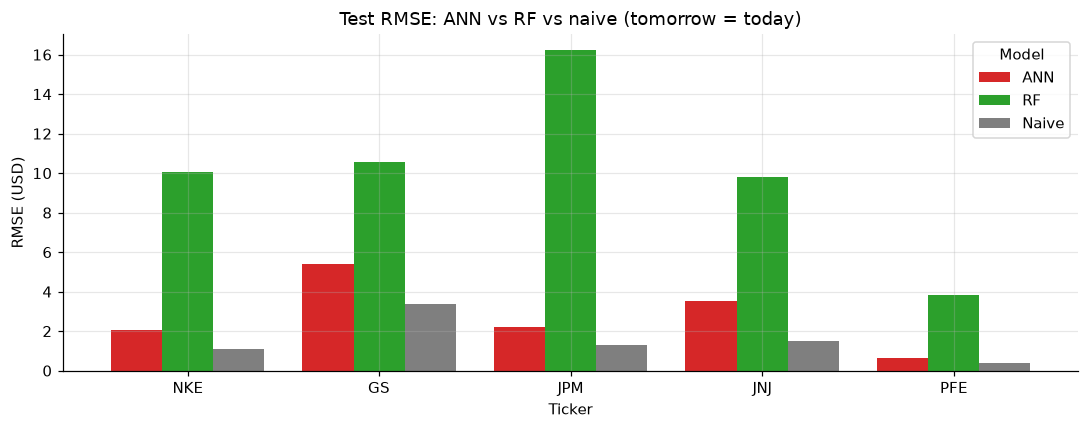

In [21]:
cmp = results.pivot(index="Ticker", columns="Model", values="RMSE")[["ANN", "RF", "Naive"]].loc[list(TICKERS)]
display(cmp.round(3))
ax = cmp.plot.bar(figsize=(10, 4), color=["C3", "C2", "C7"], rot=0, width=0.8)
ax.set_title("Test RMSE: ANN vs RF vs naive (tomorrow = today)"); ax.set_ylabel("RMSE (USD)")
plt.tight_layout(); plt.show()

### 7.1 Random Forest extrapolation limit
Trees can only output values seen during training. When test prices go above the training maximum, RF predictions flatten out.

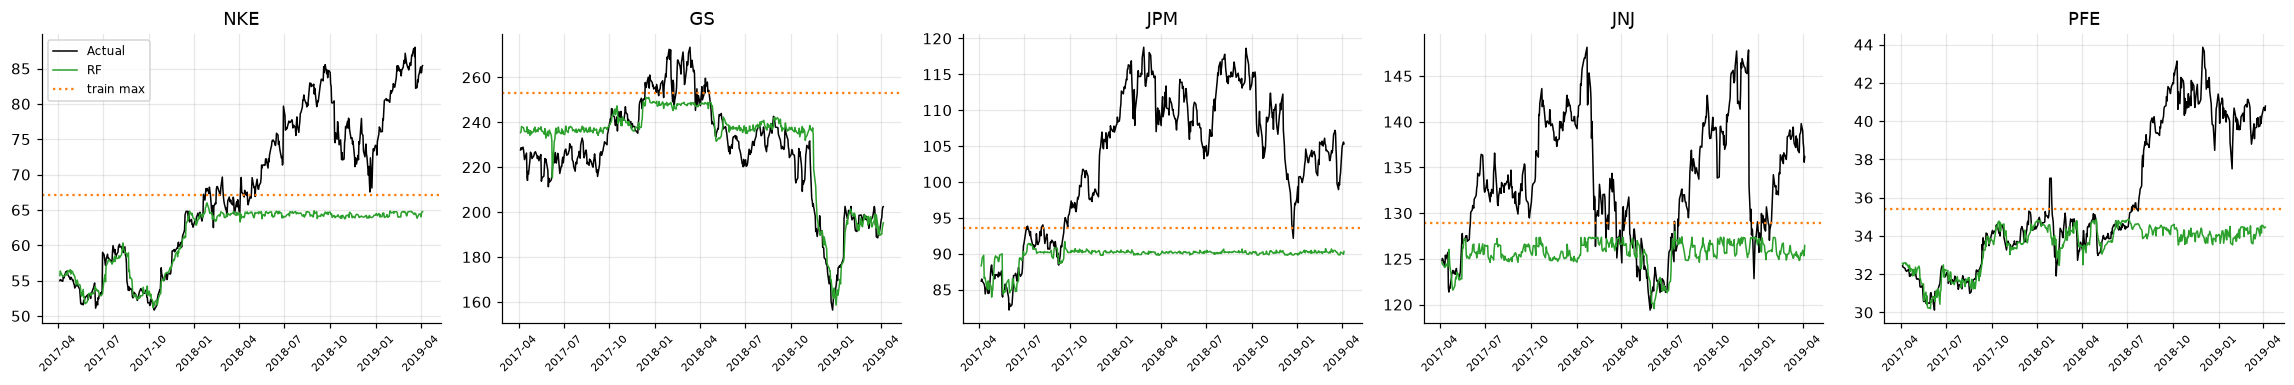

In [22]:
fig, axes = plt.subplots(1, len(TICKERS), figsize=(4.2 * len(TICKERS), 3.6))
for ax, t in zip(axes, TICKERS):
    p = preds[t]; ymax = splits[t][1].max()
    ax.plot(p.index, p.Actual, "k", lw=1, label="Actual")
    ax.plot(p.index, p.RF, "C2", lw=1, label="RF")
    ax.axhline(ymax, color="C1", ls=":", label="train max")
    ax.set_title(t); ax.tick_params(axis="x", rotation=45, labelsize=7)
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 8. Scale-free variant (extension, not in the paper)
The paper feeds raw price levels (MA7, MA14, MA21) into the models. That causes the extrapolation failure in Section 7.1. A small change fixes it: express each input **relative to MA7**, and predict the **ratio** `Next_Close / MA7 - 1`. The models then learn patterns that hold at any price level. The paper's information set is unchanged; only the representation differs.

| Input | Scale-free form |
|---|---|
| H-L, O-C, STD7 | divided by MA7 |
| MA14, MA21 | MA14/MA7 - 1, MA21/MA7 - 1 |
| Volume | log(Volume / 21-day mean volume) |

In [23]:
def make_relative(d):
    ref = d["MA7"]
    X = pd.DataFrame({"H-L/MA7": d["H-L"] / ref, "O-C/MA7": d["O-C"] / ref,
                      "MA14/MA7": d["MA14"] / ref - 1, "MA21/MA7": d["MA21"] / ref - 1,
                      "STD7/MA7": d["STD7"] / ref,
                      "logVolRel": np.log(d["Volume"] / d["Volume"].rolling(21).mean())}, index=d.index).fillna(0)
    return X, d[TARGET] / ref - 1, ref

rf_rel = lambda: RandomForestRegressor(n_estimators=500, min_samples_leaf=20, max_features=0.5, n_jobs=-1, random_state=SEED)
preds_rel, rows_rel, rf_rel_models = {}, [], {}
for t in TICKERS:
    d = feat[t]; X, y, ref = make_relative(d)
    tr, te = d.index < SPLIT_DATE, d.index >= SPLIT_DATE
    p = preds[t][["Actual", "Naive"]].copy()
    for name, mdl in [("ANN-rel", build_ann()), ("RF-rel", rf_rel())]:
        mdl.fit(X[tr], y[tr])
        p[name] = (mdl.predict(X[te]) + 1) * ref[te].values
        if name == "RF-rel": rf_rel_models[t] = mdl
    preds_rel[t] = p
    for m in ["ANN-rel", "RF-rel"]:
        rows_rel.append({"Ticker": t, "Company": TICKERS[t], "Model": m,
                         "RMSE": rmse(p.Actual, p[m]), "MAPE (%)": mape(p.Actual, p[m]), "MBE": mbe(p.Actual, p[m])})
all_results = pd.concat([results, pd.DataFrame(rows_rel)], ignore_index=True)
all_results.pivot(index="Ticker", columns="Model", values="RMSE").loc[list(TICKERS),
    ["ANN", "RF", "ANN-rel", "RF-rel", "Naive"]].round(3)

Model,ANN,RF,ANN-rel,RF-rel,Naive
Ticker,,,,,
NKE,2.051,10.034,1.426,1.468,1.112
GS,5.397,10.584,4.842,4.915,3.361
JPM,2.233,16.225,1.771,1.805,1.281
JNJ,3.536,9.794,2.038,2.153,1.512
PFE,0.623,3.851,0.569,0.571,0.404


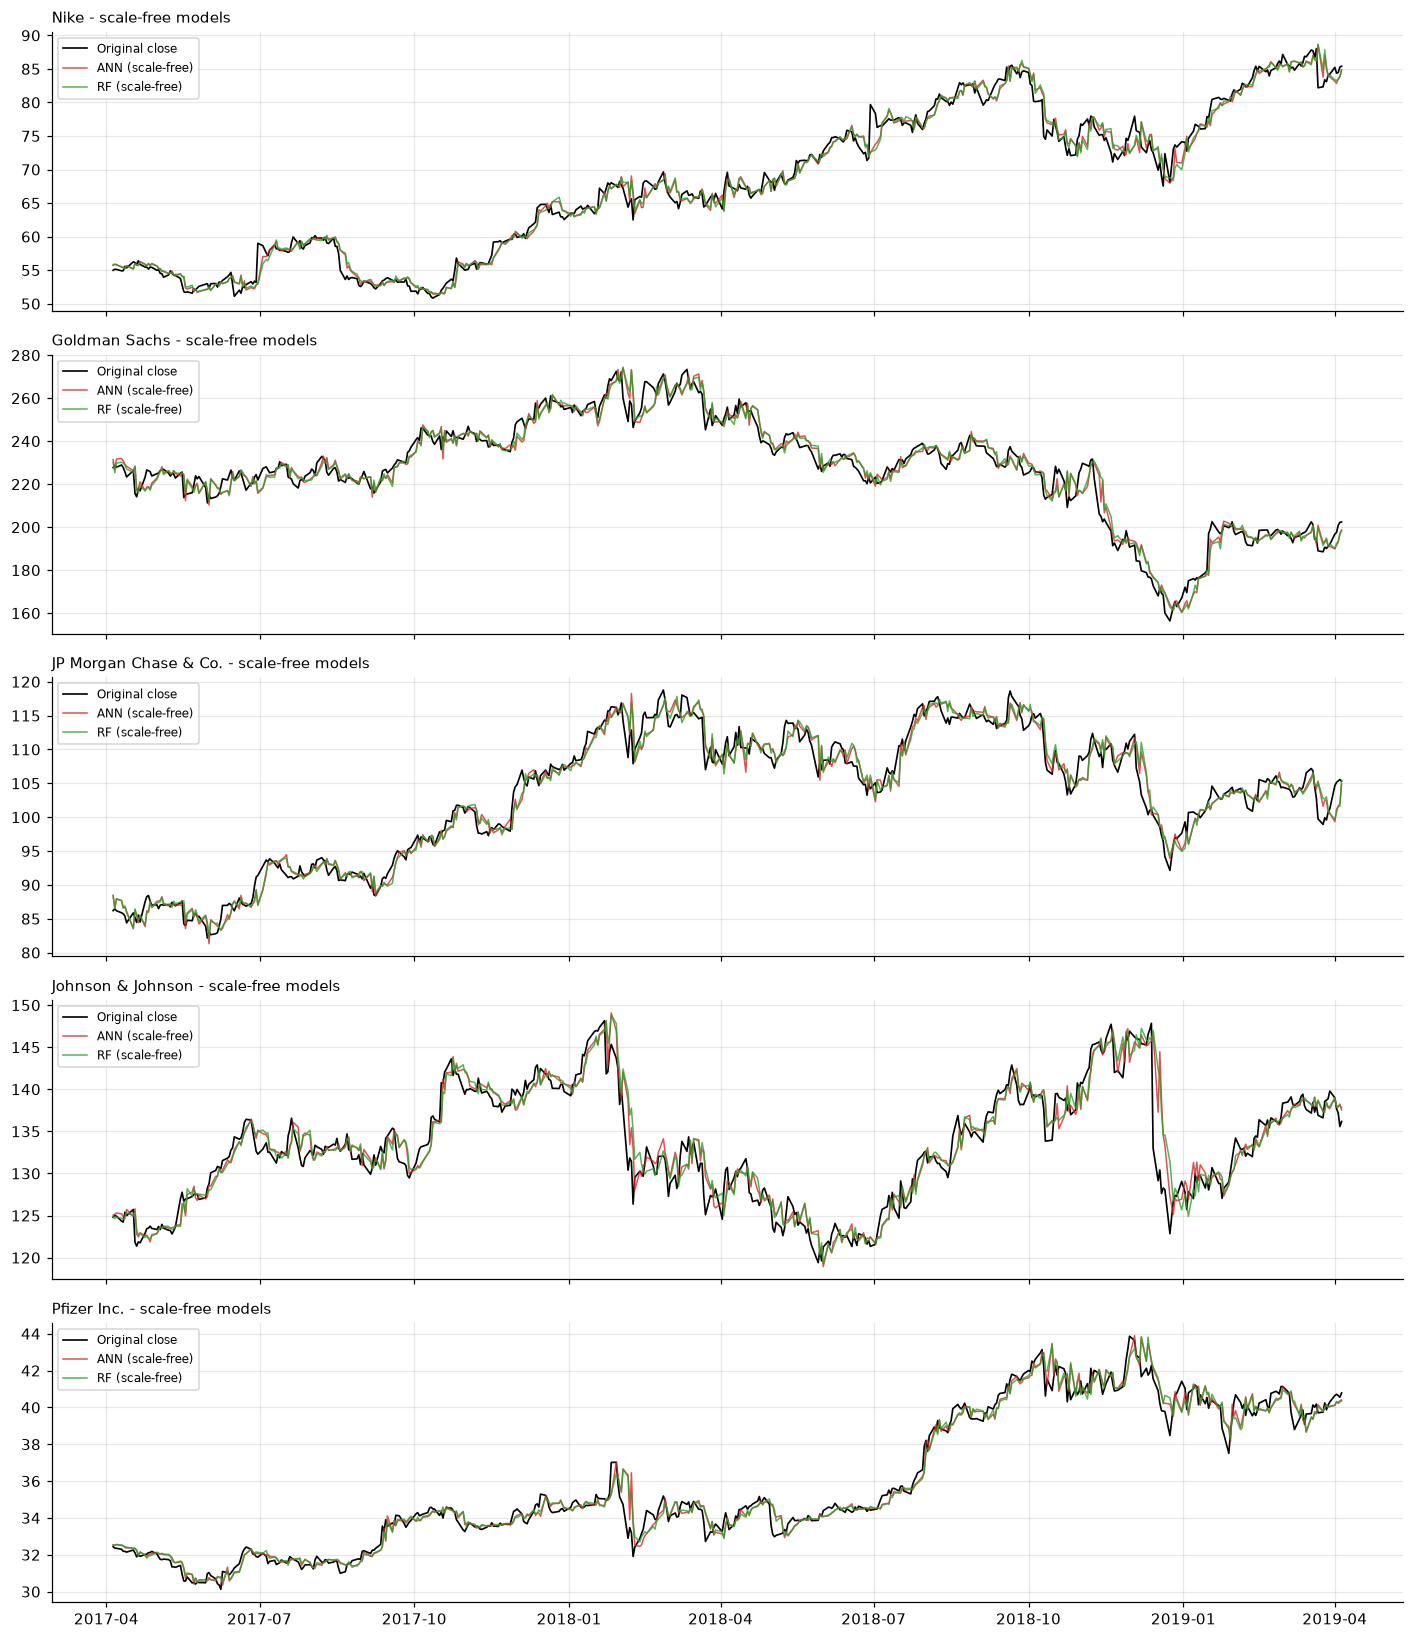

In [24]:
fig, axes = plt.subplots(len(TICKERS), 1, figsize=(13, 3 * len(TICKERS)), sharex=True)
for ax, t in zip(axes, TICKERS):
    p = preds_rel[t]
    ax.plot(p.index, p.Actual, "k", lw=1.1, label="Original close")
    ax.plot(p.index, p["ANN-rel"], "C3", lw=1, alpha=0.8, label="ANN (scale-free)")
    ax.plot(p.index, p["RF-rel"], "C2", lw=1, alpha=0.8, label="RF (scale-free)")
    ax.set_title(f"{TICKERS[t]} - scale-free models", loc="left", fontsize=10); ax.legend(fontsize=8, loc="upper left")
plt.tight_layout(); plt.show()

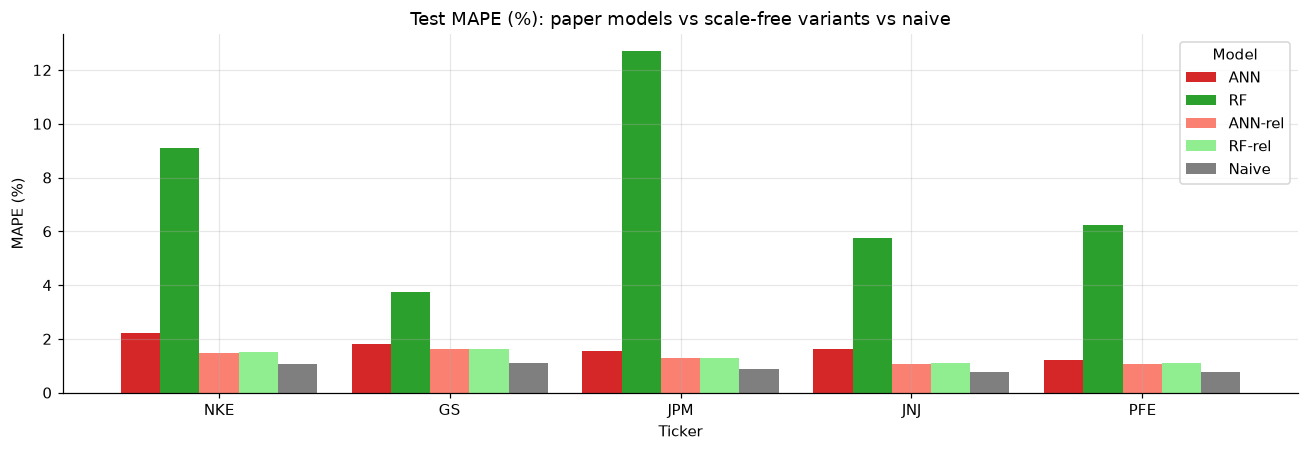

In [25]:
cmp2 = all_results.pivot(index="Ticker", columns="Model", values="MAPE (%)").loc[list(TICKERS), ["ANN", "RF", "ANN-rel", "RF-rel", "Naive"]]
ax = cmp2.plot.bar(figsize=(12, 4.2), rot=0, width=0.85, color=["C3", "C2", "salmon", "lightgreen", "C7"])
ax.set_title("Test MAPE (%): paper models vs scale-free variants vs naive"); ax.set_ylabel("MAPE (%)")
plt.tight_layout(); plt.show()

## 9. Summary

In [26]:
best = r.loc[r.groupby("Ticker")["RMSE"].idxmin(), ["Company", "Model", "RMSE", "MAPE (%)", "MBE"]]
print("Paper setup - better of ANN / RF per company (lowest RMSE):")
display(best.set_index("Company").round(4))
print("\nMean across companies:")
display(all_results.groupby("Model")[["RMSE", "MAPE (%)", "MBE"]].mean().round(4))

Paper setup - better of ANN / RF per company (lowest RMSE):


,Model,RMSE,MAPE (%),MBE
Company,,,,
Goldman Sachs,ANN,5.3968,1.7917,0.5103
Johnson & Johnson,ANN,3.5362,1.6142,-0.0842
JP Morgan Chase & Co.,ANN,2.2333,1.5532,0.2192
Nike,ANN,2.0512,2.2250,0.5063
Pfizer Inc.,ANN,0.6235,1.2278,0.1081



Mean across companies:


,RMSE,MAPE (%),MBE
Model,,,
ANN,2.7682,1.6824,0.2519
ANN-rel,2.1294,1.3015,-0.0342
Naive,1.5339,0.9136,0.0163
RF,10.0978,7.5018,5.3912
RF-rel,2.1822,1.3234,-0.0474


**Takeaways**
- With the paper's exact setup, the **ANN beats the RF for all five companies**, which agrees with the paper's conclusion. Its error is higher than the paper's Table 2, though: MAPE is about 1.2–2.2% here versus 0.7–1.1% in the paper. The paper's hyper-parameters are not given, so an exact match is not possible.
- The **naive "tomorrow = today" baseline gives RMSE almost identical to the paper's Table 2** (for example JPM 1.28 vs 1.28, PFE 0.40 vs 0.42, NKE 1.11 vs 1.10). The paper's reported accuracy is therefore what a persistence forecast already achieves. Low RMSE/MAPE on next-day price levels does not show real predictive skill.
- On raw price features, the Random Forest cannot predict above its training-set maximum (Section 7.1), so it fails badly when a stock reaches new highs in the test period. The paper does not mention this.
- Making the inputs and target relative to MA7 (Section 8) fixes the RF failure and improves the ANN. Neither model clearly beats the naive baseline, which is expected for daily stock prices.
- To use other stocks or dates, edit the configuration cell in Section 1 and re-run all cells.